In [2]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from pathlib import Path
import torch

## Training data

`Facial` maps **N frames onto one image**, so a training item is a whole identity: several
anonymized observations of a person, and the single clear image the decoder should produce from
them. `meles.training.facial.FacialFrames` assembles those items — it is to `Facial` what
`AnonymizedPairs` is to pix2pix.

- The **inputs** are frames from `ytfaces.parquet`, anonymized at their native resolution and
  *then* aligned to 112x112. That order matters: the pipeline anonymizes a frame at whatever size
  it is, so blurring a 112x112 crop would fit a radius the model never meets again at inference.
- The **target** is the frame picked in `07_target_selection.ipynb` — the one a recogniser
  identifies best among each identity's most frontal. Pose consistency matters because
  `FacialAggregator` pools with a *fixed* learned query, so nothing tells the decoder which pose
  to emit; scattered target poses leave it only their average to learn.
- The face is located on the **clear** frame, and that area is used to both anonymize and align.
  A black bar is precisely what a detector cannot find, so detecting on the anonymized frame
  would hand the model letterboxed whole frames for the anonymization that matters most.
- Input frames come from the identity's **other videos**, so the decoder cannot reconstruct the
  target off its own shot's background and lighting instead of off the face.

The split holds out **identities, not frames**. This trains on the same dataset the experiment
scores, so splitting by frame would put the same face on both sides and the validation loss would
only measure memorisation. Holding identities out is what keeps the decoder's prior from
containing the gallery — the trap `meles.training.pairs` avoids by training pix2pix on CelebA.

In [3]:
from torch.utils.data import DataLoader

from meles.training import FacialFrames, split_identities

DATASET_PATH = Path("../../data")

ANONYMIZER = "pixelation"  # the axis the experiment sweeps: one model per anonymization
FRAMES = 8  # N, how many anonymized observations make up one item
BATCH = 10
WORKERS = 4

structure_df = pd.read_parquet(DATASET_PATH / "ytfaces.parquet")
targets_df = pd.read_parquet(DATASET_PATH / "ytfaces_targets.parquet")

# Held out by identity, never by frame.
train_identities, validation_identities = split_identities(targets_df["identity"], validation=0.1, seed=0)

train_frames = FacialFrames(
    structure_df,
    targets_df,
    DATASET_PATH,
    anonymizer=ANONYMIZER,
    identities=train_identities,
    frames=FRAMES,
)

# 'deterministic' redraws nothing and skips the flip, so the validation loss is comparable
# between epochs rather than measured over a fresh sample each time.
validation_frames = FacialFrames(
    structure_df,
    targets_df,
    DATASET_PATH,
    anonymizer=ANONYMIZER,
    identities=validation_identities,
    frames=FRAMES,
    deterministic=True,
)

# 'persistent_workers' keeps the workers, and with them their detection caches, across epochs.
train_loader = DataLoader(
    train_frames, batch_size=BATCH, shuffle=True, num_workers=WORKERS,
    pin_memory=True, persistent_workers=True, drop_last=True,
)
validation_loader = DataLoader(
    validation_frames, batch_size=BATCH, shuffle=False, num_workers=WORKERS,
    pin_memory=True, persistent_workers=True,
)

print(f"train:      {len(train_frames):>4} identities, {len(train_loader):>3} batches")
print(f"validation: {len(validation_frames):>4} identities, {len(validation_loader):>3} batches")

train:       480 identities,  48 batches
validation:   53 identities,   6 batches


inputs (10, 8, 3, 112, 112) -> target (10, 3, 112, 112)
range  [-1.00, 1.00]


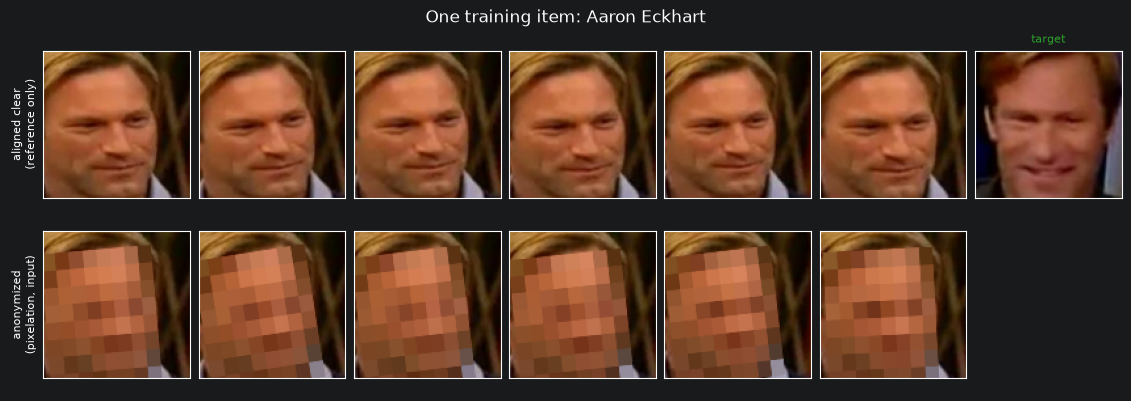

In [4]:
import cv2

# One batch, to confirm it is the shape Facial.forward takes.
inputs, target = next(iter(train_loader))
print(f"inputs {tuple(inputs.shape)} -> target {tuple(target.shape)}")
print(f"range  [{inputs.min():.2f}, {inputs.max():.2f}]")

# The same frames aligned twice: clear on top, anonymized below. The clear row is the check that
# matters -- if those faces are centred the alignment is right, and whatever the row below looks
# like is then the anonymization doing its job. Heavy anonymization on its own is indistinguishable
# from a misaligned crop, which is why both rows are here.
SHOWN = 6
identity = train_frames.identities[0]
paths = train_frames.pool[identity][:SHOWN]

fig, axes = plt.subplots(2, SHOWN + 1, figsize=(1.6 * (SHOWN + 1), 3.9), layout="constrained")
for column, path in enumerate(paths):
    axes[0, column].imshow(cv2.cvtColor(train_frames.crop(path, anonymize=False, flip=False), cv2.COLOR_BGR2RGB))
    axes[1, column].imshow(cv2.cvtColor(train_frames.crop(path, anonymize=True, flip=False), cv2.COLOR_BGR2RGB))

# The target sits in the clear row; the model only ever sees it as the thing to produce.
target_crop = train_frames.crop(train_frames.target[identity], anonymize=False, flip=False)
axes[0, SHOWN].imshow(cv2.cvtColor(target_crop, cv2.COLOR_BGR2RGB))
axes[0, SHOWN].set_title("target", fontsize=8, color="tab:green")
axes[1, SHOWN].set_axis_off()

axes[0, 0].set_ylabel("aligned clear\n(reference only)", fontsize=8)
axes[1, 0].set_ylabel(f"anonymized\n({ANONYMIZER}, input)", fontsize=8)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle(f"One training item: {identity.replace('_', ' ')}", fontsize=12)
plt.show()

In [ ]:
from meles.frame_aggregation.facial import Facial

EPOCHS = 100

model = Facial(weights="backbone.pth").cuda()

In [2]:
# Stage 1 (encoder frozen)

model.set_encoder_frozen(True)
parameters = model.train_parameters()
opt = torch.optim.AdamW(parameters, lr=1e-4, weight_decay=5e-4)

epoch = 0
while epoch < EPOCHS:


In [ ]:
# Stage 2 (encoder fine-tune)

model.set_encoder_frozen(False)
parameters = [
    {"params": model.fine_parameters(), "lr": 1e-5},
    {"params": model.train_parameters(), "lr": 1e-4},
]
opt = torch.optim.AdamW(parameters, weight_decay=5e-4)